In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc
import sklearn as sk
import seaborn as sns
%matplotlib inline

# For Filtering the warnings
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df_ncd = pd.read_csv('/content/bgd2018.csv')

In [ ]:
df_ncd.head()

,pid,psu,stratum,division,urbanrural,wstep1,wstep2,wstep3,agerange,sex,...,b5,b6,b8,b9,b10,b14,b15,b16,b17,ldl
0,E11-1-1,1,102,1,Urban,2289.934,2289.934,2225.453,18-29,0,...,97.000,NaN,179.000,NaN,2.000,37.600,30.000,105.000,37.000,121.000
1,E11-10-1,1,102,1,Urban,1202.909,1202.909,NaN,45-59,0,...,NaN,2.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E11-100-1,48,101,1,Rural,7604.362,7604.362,12915.716,30-44,0,...,100.000,NaN,168.000,NaN,2.000,21.000,15.000,140.000,29.000,111.000
3,E11-101-1,49,101,1,Rural,7710.942,7710.942,7493.812,18-29,0,...,90.000,NaN,134.000,NaN,2.000,29.000,20.000,68.000,43.000,77.400
4,E11-102-1,49,101,1,Rural,4049.076,4049.076,6877.199,30-44,0,...,99.000,NaN,231.000,NaN,2.000,235.000,120.000,235.000,33.000,151.000


In [ ]:
df_ncd.shape

(8185, 425)

In [ ]:
columns_to_keep = ['urbanrural', 'division', 'sex', 'age', 't1', 'a4', 'h2a', 'h7a', 'h13a', 'h20f', 'h20a', 'cx1', 'cx6', 'm14', 'm6a', 'm6b', 'm11', 'm12','m16c', 'b5', 'b8','b16', 'b17', 'ldl']

df_ncd = df_ncd[columns_to_keep]

In [ ]:
df_ncd.rename(columns={ 't1': 'currently_smoking', 'a4': 'drinking_alcohol', 'h2a': 'had_high_bp', 'h7a': 'had_high_glucose', 'h13a': 'high_cholesterol', 'h20f': 'advice_to_lose_weight', 'h20a': 'advice_to_not_smoke', 'cx1': 'cervical_cancer_screening_test', 'cx6': 'result_of_cervical_cancer_test', 'm14': 'waist', 'm6a': 'systolic','m6b' : 'diastolic', 'm11' : 'hight', 'm12': 'weight', 'm16c': 'heart_rate_reading', 'b5': 'fasting_blood_glucose', 'b8': 'cholsterol', 'b16': 'triglycerides', 'b17': 'hdl'}, inplace=True)

In [ ]:
df_ncd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8185 entries, 0 to 8184
Data columns (total 24 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   urbanrural                      8185 non-null   object 
 1   division                        8185 non-null   int64  
 2   sex                             8185 non-null   int64  
 3   age                             8185 non-null   int64  
 4   currently_smoking               8185 non-null   int64  
 5   drinking_alcohol                306 non-null    float64
 6   had_high_bp                     6060 non-null   float64
 7   had_high_glucose                2386 non-null   float64
 8   high_cholesterol                514 non-null    float64
 9   advice_to_lose_weight           3977 non-null   float64
 10  advice_to_not_smoke             3977 non-null   float64
 11  cervical_cancer_screening_test  4364 non-null   float64
 12  result_of_cervical_cancer_test  27

In [ ]:
pd.set_option('display.float_format', lambda x: '%.3f' % x)
df_ncd.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
division,8185.000,4.510,2.280,1.000,3.000,5.000,6.000,8.000
sex,8185.000,0.465,0.499,0.000,0.000,0.000,1.000,1.000
age,8185.000,39.075,12.300,18.000,30.000,38.000,48.000,69.000
currently_smoking,8185.000,1.765,0.424,1.000,2.000,2.000,2.000,2.000
drinking_alcohol,306.000,5.389,1.224,1.000,5.000,6.000,6.000,6.000
had_high_bp,6060.000,1.767,0.422,1.000,2.000,2.000,2.000,2.000
had_high_glucose,2386.000,1.775,0.418,1.000,2.000,2.000,2.000,2.000
high_cholesterol,514.000,1.514,0.500,1.000,1.000,2.000,2.000,2.000
advice_to_lose_weight,3977.000,1.801,0.399,1.000,2.000,2.000,2.000,2.000
advice_to_not_smoke,3977.000,1.793,0.406,1.000,2.000,2.000,2.000,2.000


In [ ]:
df_ncd.shape

(8185, 24)

In [ ]:
df_ncd.isnull()


,urbanrural,division,sex,age,currently_smoking,drinking_alcohol,had_high_bp,had_high_glucose,high_cholesterol,advice_to_lose_weight,...,systolic,diastolic,hight,weight,heart_rate_reading,fasting_blood_glucose,cholsterol,triglycerides,hdl,ldl
0,False,False,False,False,False,True,False,True,True,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,True,False,False,True,False,...,False,False,False,False,False,True,True,True,True,True
2,False,False,False,False,False,True,False,True,True,True,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,True,False,True,True,True,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,True,False,True,True,True,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8180,False,False,False,False,False,True,False,False,True,True,...,False,False,False,False,False,False,False,False,False,False
8181,False,False,False,False,False,True,False,True,True,False,...,False,False,False,False,False,False,False,False,False,False
8182,False,False,False,False,False,True,True,True,True,True,...,False,False,False,False,False,False,False,False,False,False
8183,False,False,False,False,False,True,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
df_ncd.isnull().sum()/len(df_ncd)*100

,0
urbanrural,0.000
division,0.000
sex,0.000
age,0.000
currently_smoking,0.000
drinking_alcohol,96.261
had_high_bp,25.962
had_high_glucose,70.849
high_cholesterol,93.720
advice_to_lose_weight,51.411


In [ ]:
import missingno as msno

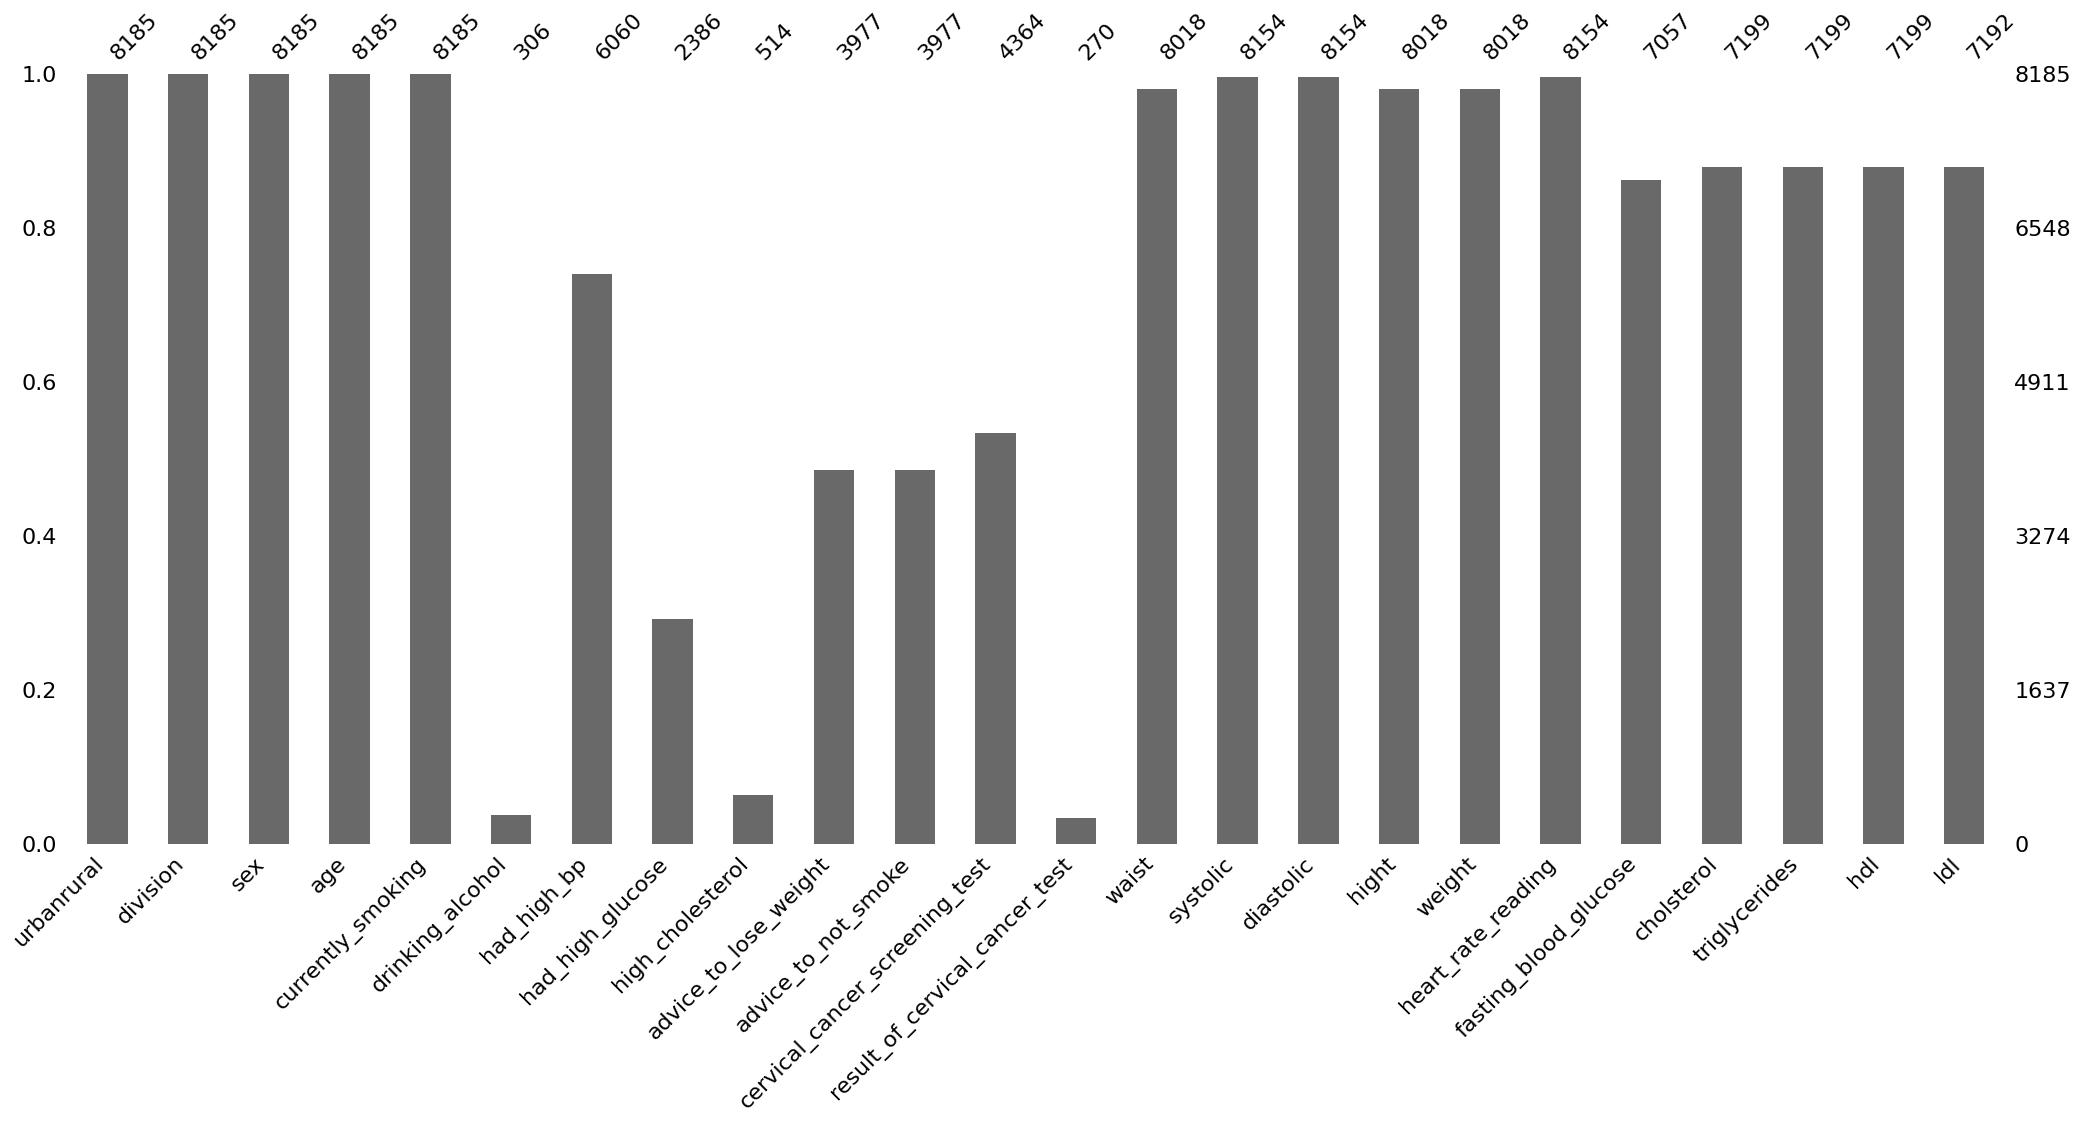

In [ ]:
msno.bar(df_ncd)
plt.show()

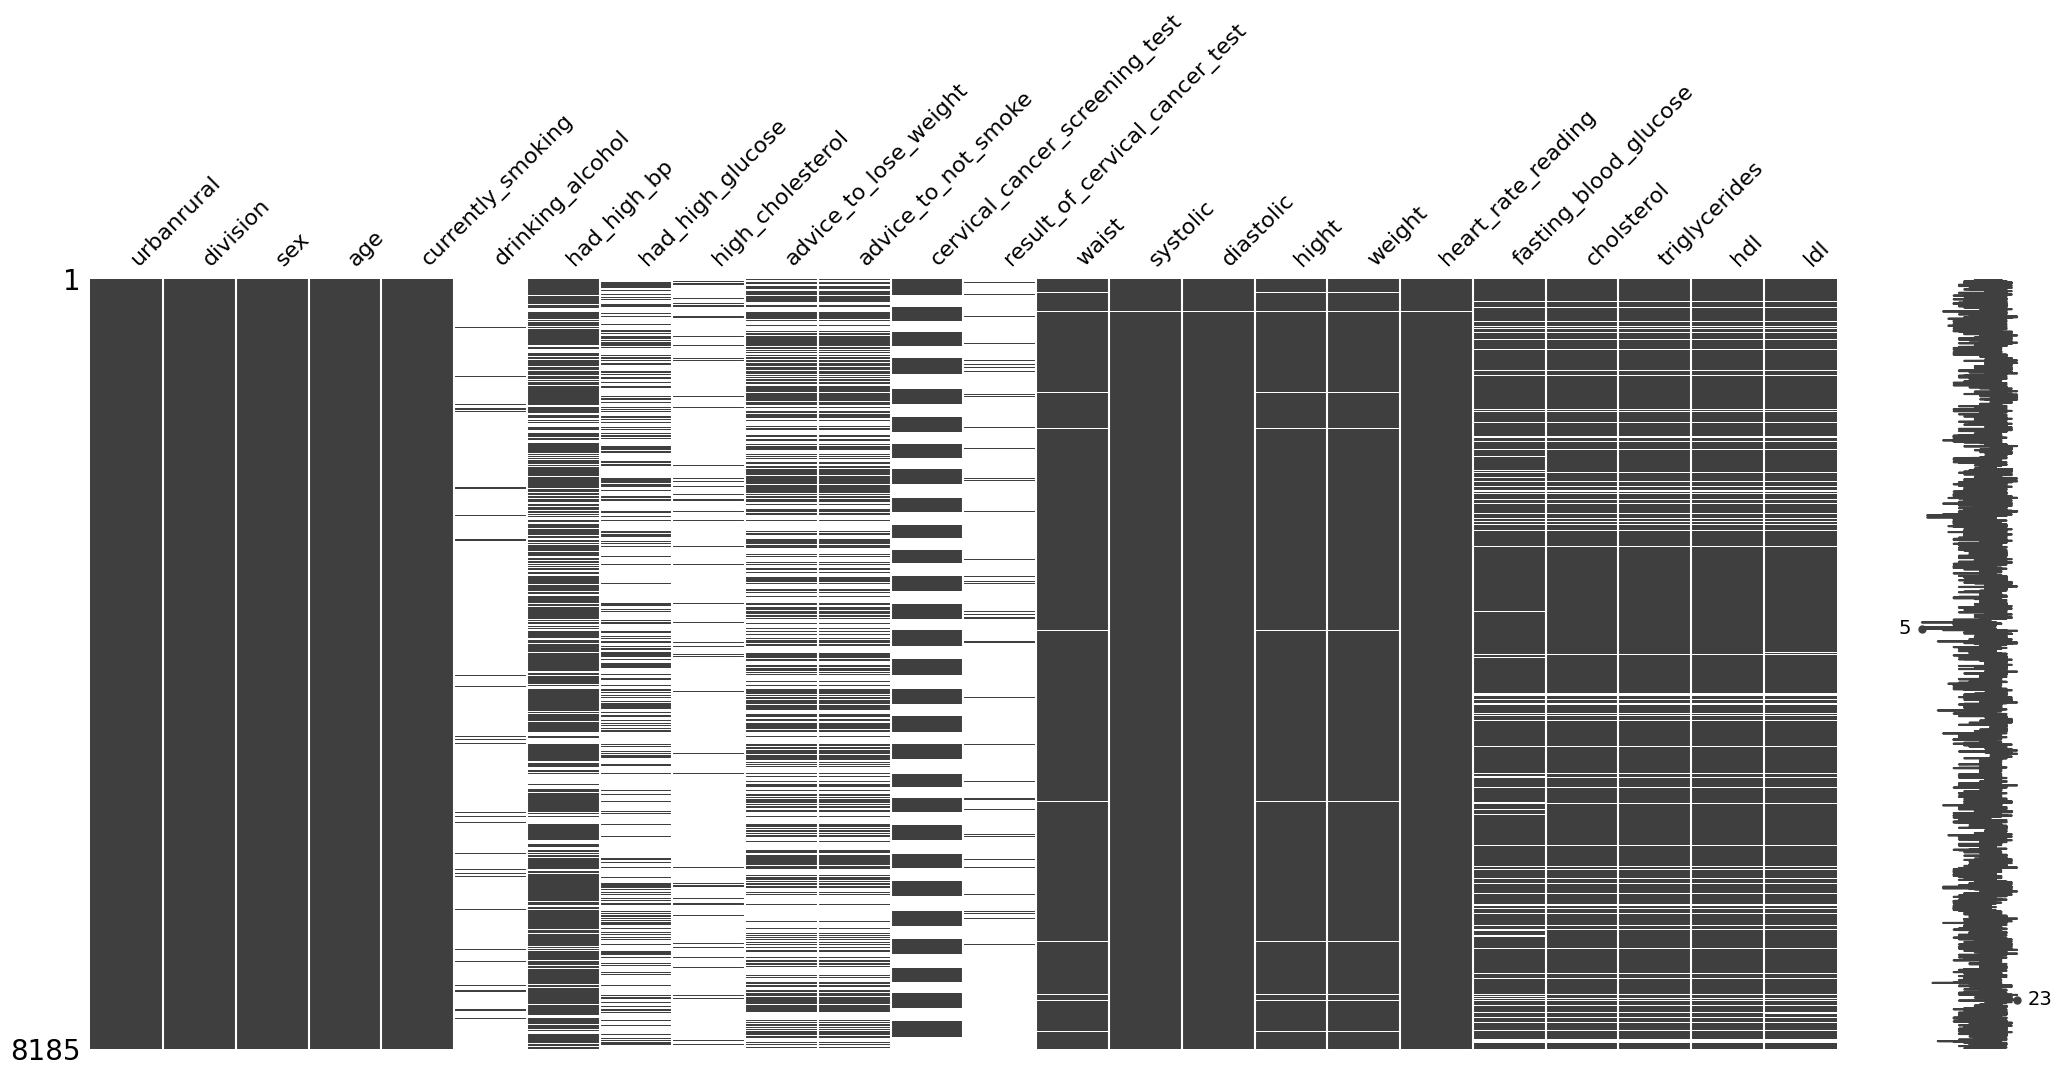

In [ ]:
msno.matrix(df_ncd)
plt.show()

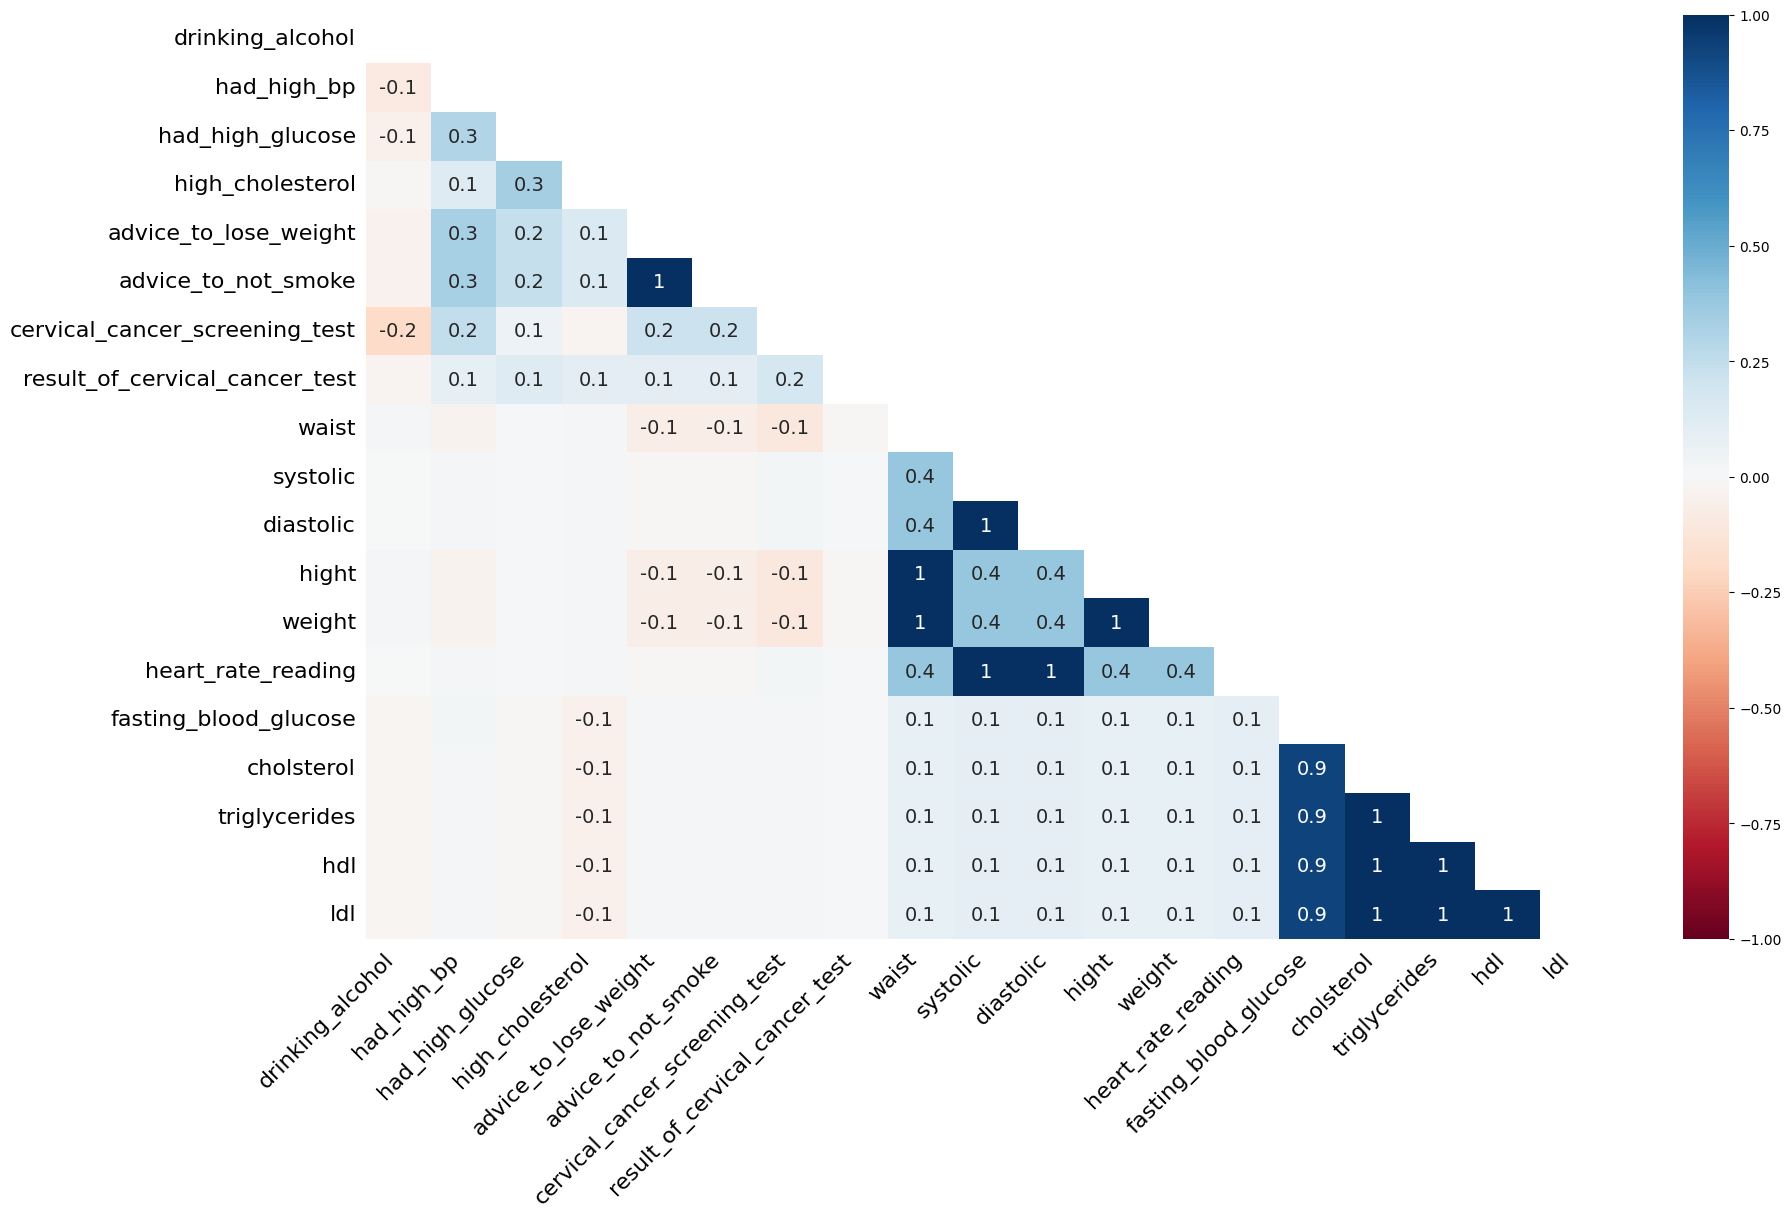

In [ ]:
msno.heatmap(df_ncd)
plt.show()

In [ ]:
# Replace missing values in continuous columns with mean
columns_to_replace_with_mean = ['drinking_alcohol', 'had_high_bp', 'had_high_glucose', 'high_cholesterol', 'advice_to_lose_weight', 'advice_to_not_smoke', 'cervical_cancer_screening_test','result_of_cervical_cancer_test', 'hight', 'weight','waist','systolic','diastolic','heart_rate_reading', 'fasting_blood_glucose', 'cholsterol', 'triglycerides', 'hdl', 'ldl']
for col in columns_to_replace_with_mean:
    df_ncd[col].fillna(df_ncd[col].mean(), inplace=True)


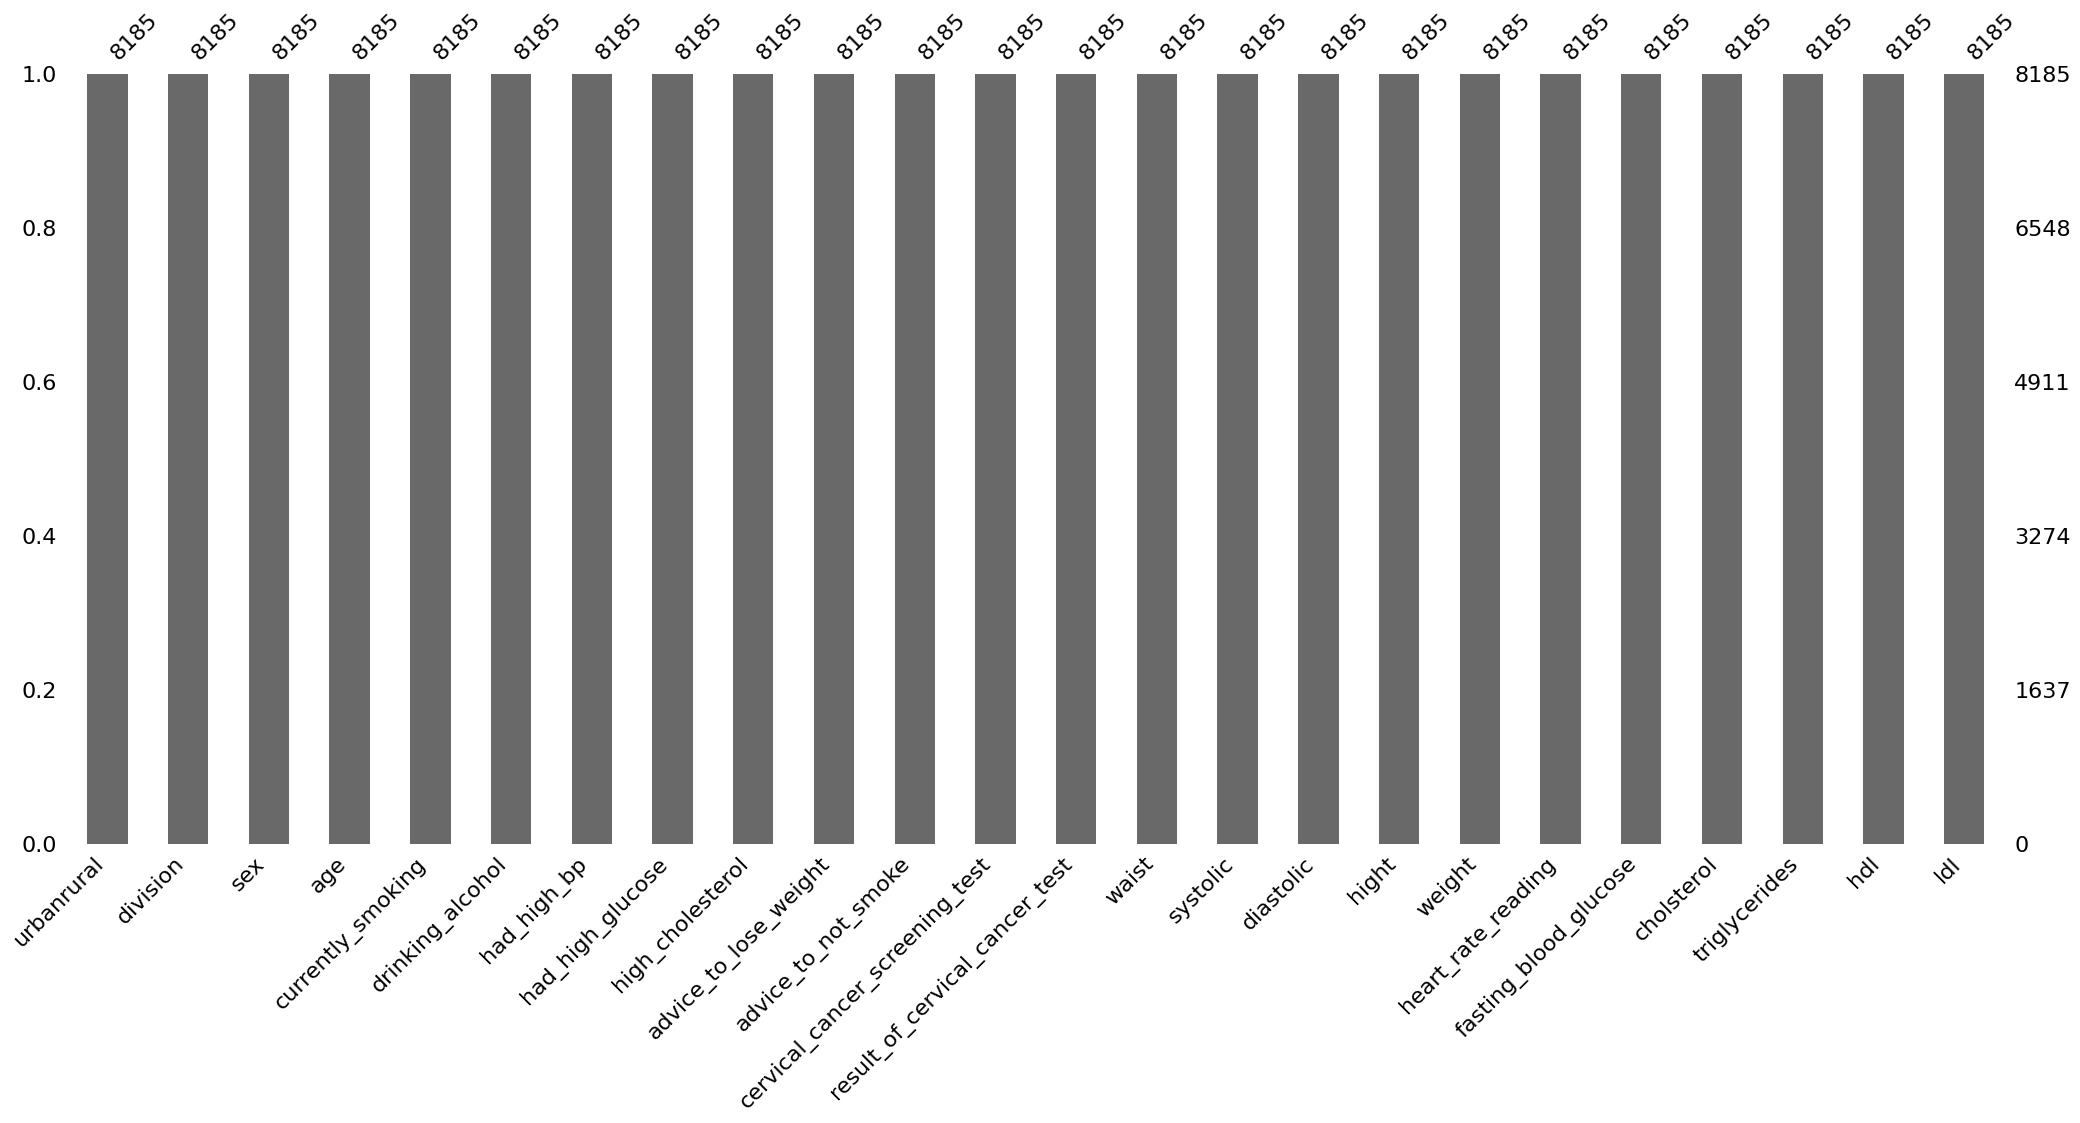

In [ ]:
msno.bar(df_ncd)
plt.show()

In [ ]:
(df_ncd.isnull().sum())*100/len(df_ncd)

,0
urbanrural,0.000
division,0.000
sex,0.000
age,0.000
currently_smoking,0.000
drinking_alcohol,0.000
had_high_bp,0.000
had_high_glucose,0.000
high_cholesterol,0.000
advice_to_lose_weight,0.000


In [ ]:
df_ncd.duplicated().sum()

0

In [ ]:
pip install pandas seaborn matplotlib


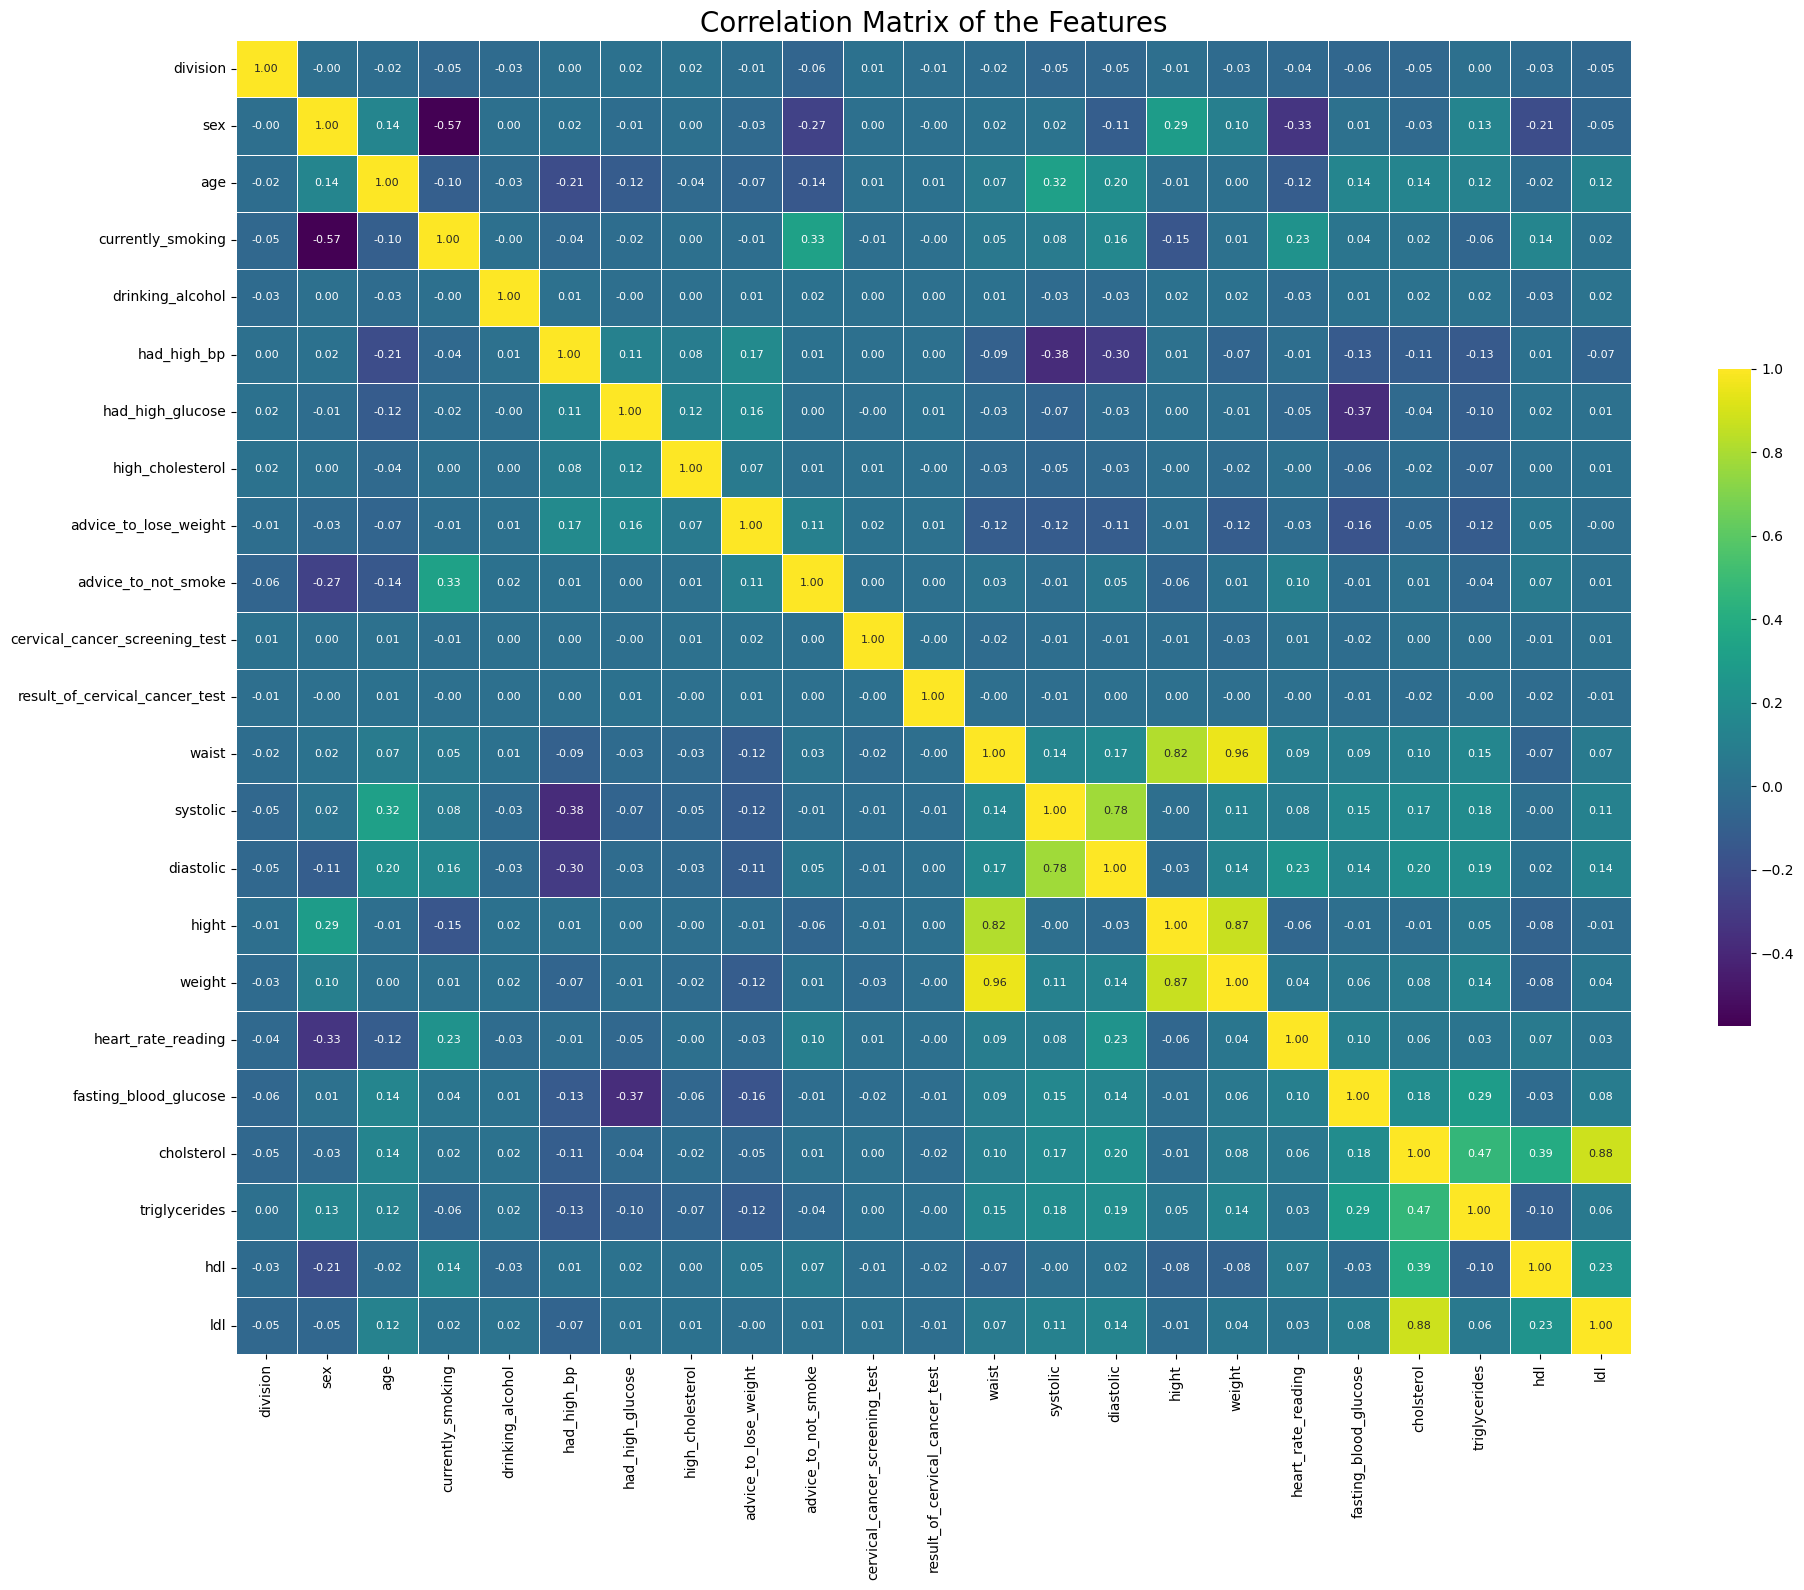

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the correlation matrix
df = df_ncd
# Select only numerical columns for correlation calculation
numerical_df = df.select_dtypes(include=['number'])
correlation_matrix = numerical_df.corr()

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(20, 16))
heatmap = sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='viridis', linewidths=0.5, cbar_kws={'shrink': .5}, annot_kws={"size": 8})
plt.title('Correlation Matrix of the Features', fontsize=20)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()  # Adjust layout to ensure everything fits without overlap
plt.show()

In [ ]:
df_ncd.shape

(8185, 24)

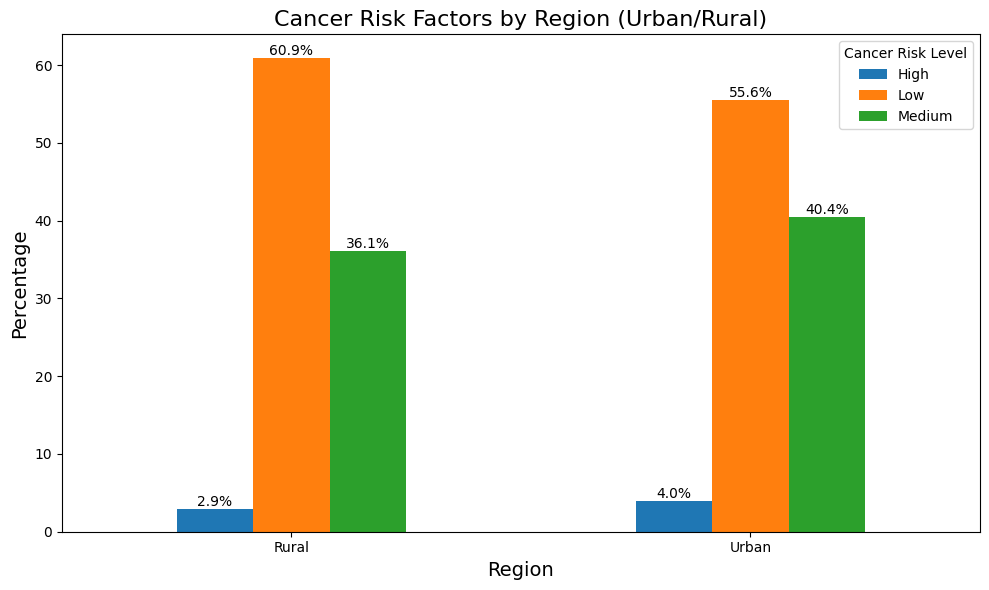

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
file_path = '/content/bgd2018.csv'  # Update the file path
df_ncd = pd.read_csv(file_path)

# Keeping the relevant columns
columns_to_keep = ['urbanrural', 'division', 'sex', 'age', 't1', 'a4', 'h2a', 'h7a',
                   'h13a', 'h20f', 'h20a', 'cx1', 'cx6', 'm14', 'm6a', 'm6b',
                   'm11', 'm12', 'm16c', 'b5', 'b8', 'b16', 'b17', 'ldl']
df_ncd = df_ncd[columns_to_keep]

# Renaming columns for better readability
df_ncd.rename(columns={
    't1': 'currently_smoking',
    'a4': 'drinking_alcohol',
    'h2a': 'had_high_bp',
    'h7a': 'had_high_glucose',
    'h13a': 'high_cholesterol',
    'h20f': 'advice_to_lose_weight',
    'h20a': 'advice_to_not_smoke',
    'cx1': 'cervical_cancer_screening_test',
    'cx6': 'result_of_cervical_cancer_test',
    'm14': 'waist',
    'm6a': 'systolic',
    'm6b': 'diastolic',
    'm11': 'height',
    'm12': 'weight',
    'm16c': 'heart_rate_reading',
    'b5': 'fasting_blood_glucose',
    'b8': 'cholesterol',
    'b16': 'triglycerides',
    'b17': 'hdl'
}, inplace=True)

# Classify cancer risk levels
def classify_cancer_risk(row):
    risk_score = 0
    if row['currently_smoking'] == 1:  # Smoker
        risk_score += 1
    if row['drinking_alcohol'] == 1:  # Alcohol consumption
        risk_score += 1
    if row['had_high_bp'] == 1 or row['had_high_glucose'] == 1 or row['high_cholesterol'] == 1:  # High BP, glucose, cholesterol
        risk_score += 1

    if risk_score == 0:
        return 'Low'
    elif risk_score == 1:
        return 'Medium'
    else:
        return 'High'

# Apply the classification function
df_ncd['cancer_risk'] = df_ncd.apply(classify_cancer_risk, axis=1)

# Group by urban/rural and cancer risk to get counts
risk_counts = df_ncd.groupby(['urbanrural', 'cancer_risk']).size().unstack()

# Calculate the percentage of each risk level within each region
risk_percentages = risk_counts.div(risk_counts.sum(axis=1), axis=0) * 100

# Plotting the clustered bar chart
ax = risk_percentages.plot(kind='bar', stacked=False, color=['#1f77b4', '#ff7f0e', '#2ca02c'], figsize=(10, 6))

# Adding percentage labels on the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=10)

plt.title('Cancer Risk Factors by Region (Urban/Rural)', fontsize=16)
plt.xlabel('Region', fontsize=14)
plt.ylabel('Percentage', fontsize=14)
plt.xticks(rotation=0)
plt.legend(title='Cancer Risk Level')
plt.tight_layout()

# Display the plot
plt.show()


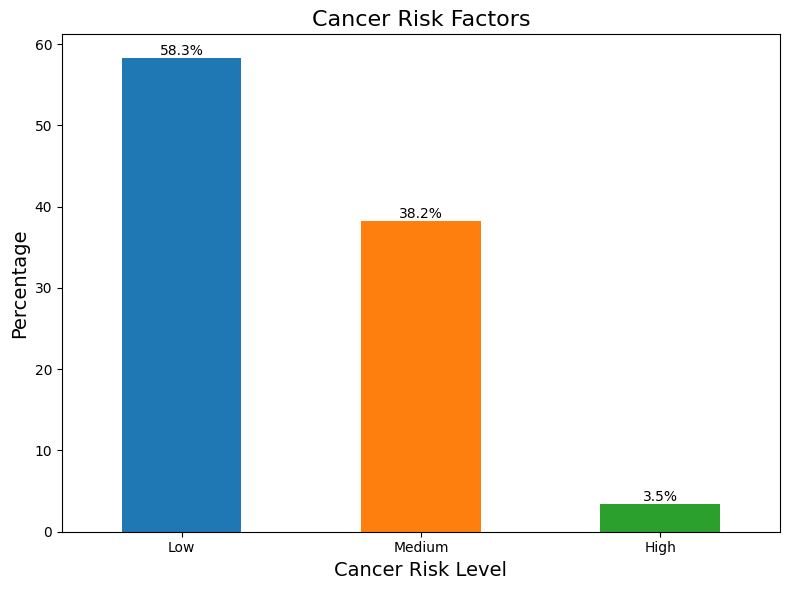

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
file_path = '/content/bgd2018.csv'  # Update the file path
df_ncd = pd.read_csv(file_path)

# Keeping the relevant columns
columns_to_keep = ['division', 'sex', 'age', 't1', 'a4', 'h2a', 'h7a', 'h13a',
                   'h20f', 'h20a', 'cx1', 'cx6', 'm14', 'm6a', 'm6b',
                   'm11', 'm12', 'm16c', 'b5', 'b8', 'b16', 'b17', 'ldl']
df_ncd = df_ncd[columns_to_keep]

# Renaming columns for better readability
df_ncd.rename(columns={
    't1': 'currently_smoking',
    'a4': 'drinking_alcohol',
    'h2a': 'had_high_bp',
    'h7a': 'had_high_glucose',
    'h13a': 'high_cholesterol',
    'h20f': 'advice_to_lose_weight',
    'h20a': 'advice_to_not_smoke',
    'cx1': 'cervical_cancer_screening_test',
    'cx6': 'result_of_cervical_cancer_test',
    'm14': 'waist',
    'm6a': 'systolic',
    'm6b': 'diastolic',
    'm11' : 'height',
    'm12': 'weight',
    'm16c': 'heart_rate_reading',
    'b5': 'fasting_blood_glucose',
    'b8': 'cholesterol',
    'b16': 'triglycerides',
    'b17': 'hdl'
}, inplace=True)

# Classify cancer risk levels
def classify_cancer_risk(row):
    risk_score = 0
    if row['currently_smoking'] == 1:  # Smoker
        risk_score += 1
    if row['drinking_alcohol'] == 1:  # Alcohol consumption
        risk_score += 1
    if row['had_high_bp'] == 1 or row['had_high_glucose'] == 1 or row['high_cholesterol'] == 1:  # High BP, glucose, cholesterol
        risk_score += 1

    if risk_score == 0:
        return 'Low'
    elif risk_score == 1:
        return 'Medium'
    else:
        return 'High'

# Apply the classification function
df_ncd['cancer_risk'] = df_ncd.apply(classify_cancer_risk, axis=1)

# Get counts of each cancer risk level
risk_counts = df_ncd['cancer_risk'].value_counts()

# Calculate the percentage of each risk level
risk_percentages = (risk_counts / risk_counts.sum()) * 100

# Plotting the bar chart
ax = risk_percentages.plot(kind='bar', color=['#1f77b4', '#ff7f0e', '#2ca02c'], figsize=(8, 6))

# Adding percentage labels on the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=10)

plt.title('Cancer Risk Factors', fontsize=16)
plt.xlabel('Cancer Risk Level', fontsize=14)
plt.ylabel('Percentage', fontsize=14)
plt.xticks(rotation=0)
plt.tight_layout()

# Display the plot
plt.show()


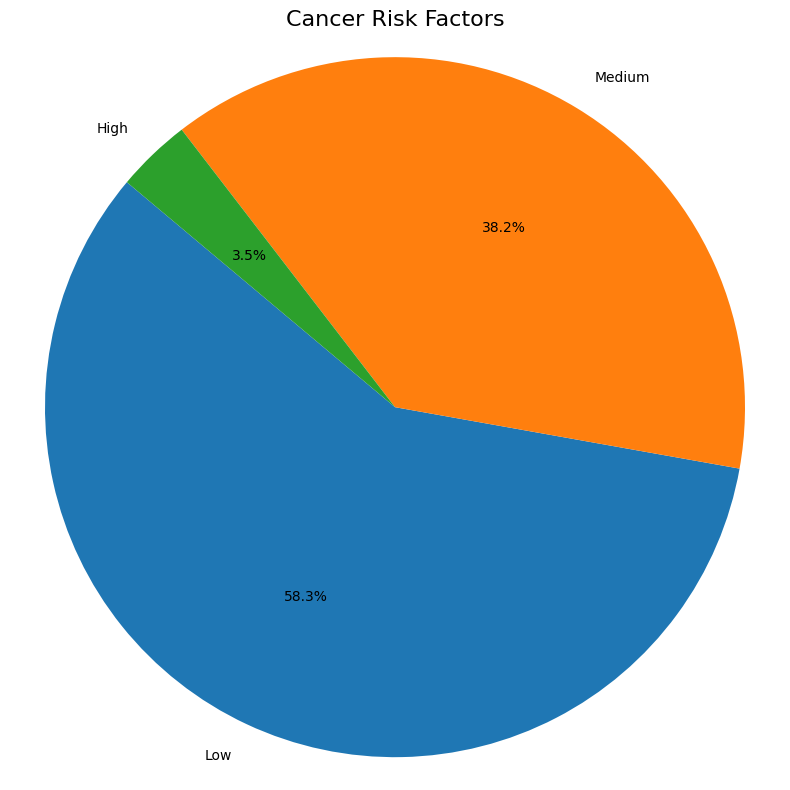

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
file_path = '/content/bgd2018.csv'  # Update the file path
df_ncd = pd.read_csv(file_path)

# Keeping the relevant columns
columns_to_keep = ['division', 'sex', 'age', 't1', 'a4', 'h2a', 'h7a', 'h13a',
                   'h20f', 'h20a', 'cx1', 'cx6', 'm14', 'm6a', 'm6b',
                   'm11', 'm12', 'm16c', 'b5', 'b8', 'b16', 'b17', 'ldl']
df_ncd = df_ncd[columns_to_keep]

# Renaming columns for better readability
df_ncd.rename(columns={
    't1': 'currently_smoking',
    'a4': 'drinking_alcohol',
    'h2a': 'had_high_bp',
    'h7a': 'had_high_glucose',
    'h13a': 'high_cholesterol',
    'h20f': 'advice_to_lose_weight',
    'h20a': 'advice_to_not_smoke',
    'cx1': 'cervical_cancer_screening_test',
    'cx6': 'result_of_cervical_cancer_test',
    'm14': 'waist',
    'm6a': 'systolic',
    'm6b': 'diastolic',
    'm11' : 'height',
    'm12': 'weight',
    'm16c': 'heart_rate_reading',
    'b5': 'fasting_blood_glucose',
    'b8': 'cholesterol',
    'b16': 'triglycerides',
    'b17': 'hdl'
}, inplace=True)

# Classify cancer risk levels
def classify_cancer_risk(row):
    risk_score = 0
    if row['currently_smoking'] == 1:  # Smoker
        risk_score += 1
    if row['drinking_alcohol'] == 1:  # Alcohol consumption
        risk_score += 1
    if row['had_high_bp'] == 1 or row['had_high_glucose'] == 1 or row['high_cholesterol'] == 1:  # High BP, glucose, cholesterol
        risk_score += 1

    if risk_score == 0:
        return 'Low'
    elif risk_score == 1:
        return 'Medium'
    else:
        return 'High'

# Apply the classification function
df_ncd['cancer_risk'] = df_ncd.apply(classify_cancer_risk, axis=1)

# Get counts of each cancer risk level
risk_counts = df_ncd['cancer_risk'].value_counts()

# Calculate the percentage of each risk level
risk_percentages = (risk_counts / risk_counts.sum()) * 100

# Plotting the pie chart
plt.figure(figsize=(8, 8))
plt.pie(risk_counts, labels=risk_counts.index, autopct='%1.1f%%', startangle=140, colors=['#1f77b4', '#ff7f0e', '#2ca02c'])

plt.title('Cancer Risk Factors', fontsize=16)
plt.axis('equal')  # Equal aspect ratio ensures that pie chart is circular.
plt.tight_layout()

# Display the plot
plt.show()


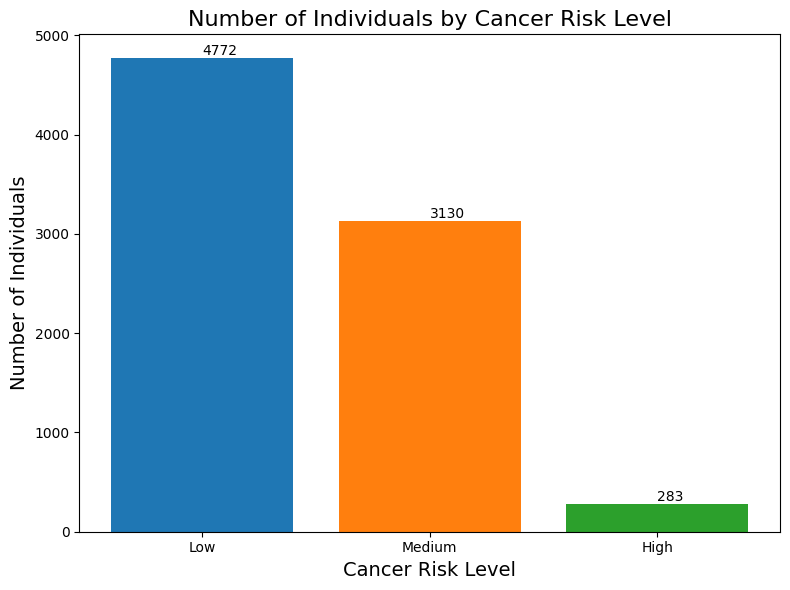

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
file_path = '/content/bgd2018.csv'  # Update the file path
df_ncd = pd.read_csv(file_path)

# Keeping the relevant columns
columns_to_keep = ['division', 'sex', 'age', 't1', 'a4', 'h2a', 'h7a', 'h13a',
                   'h20f', 'h20a', 'cx1', 'cx6', 'm14', 'm6a', 'm6b',
                   'm11', 'm12', 'm16c', 'b5', 'b8', 'b16', 'b17', 'ldl']
df_ncd = df_ncd[columns_to_keep]

# Renaming columns for better readability
df_ncd.rename(columns={
    't1': 'currently_smoking',
    'a4': 'drinking_alcohol',
    'h2a': 'had_high_bp',
    'h7a': 'had_high_glucose',
    'h13a': 'high_cholesterol',
    'h20f': 'advice_to_lose_weight',
    'h20a': 'advice_to_not_smoke',
    'cx1': 'cervical_cancer_screening_test',
    'cx6': 'result_of_cervical_cancer_test',
    'm14': 'waist',
    'm6a': 'systolic',
    'm6b': 'diastolic',
    'm11' : 'height',
    'm12': 'weight',
    'm16c': 'heart_rate_reading',
    'b5': 'fasting_blood_glucose',
    'b8': 'cholesterol',
    'b16': 'triglycerides',
    'b17': 'hdl'
}, inplace=True)

# Classify cancer risk levels
def classify_cancer_risk(row):
    risk_score = 0
    if row['currently_smoking'] == 1:  # Smoker
        risk_score += 1
    if row['drinking_alcohol'] == 1:  # Alcohol consumption
        risk_score += 1
    if row['had_high_bp'] == 1 or row['had_high_glucose'] == 1 or row['high_cholesterol'] == 1:  # High BP, glucose, cholesterol
        risk_score += 1

    if risk_score == 0:
        return 'Low'
    elif risk_score == 1:
        return 'Medium'
    else:
        return 'High'

# Apply the classification function
df_ncd['cancer_risk'] = df_ncd.apply(classify_cancer_risk, axis=1)

# Get counts of each cancer risk level
risk_counts = df_ncd['cancer_risk'].value_counts()

# Create a DataFrame for plotting
risk_counts_df = pd.DataFrame(risk_counts).reset_index()
risk_counts_df.columns = ['Cancer Risk Level', 'Number of Individuals']

# Plotting the clustered bar chart
plt.figure(figsize=(8, 6))
bars = plt.bar(risk_counts_df['Cancer Risk Level'], risk_counts_df['Number of Individuals'], color=['#1f77b4', '#ff7f0e', '#2ca02c'])

# Add counts on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, int(yval), va='bottom')  # va: vertical alignment

plt.title('Number of Individuals by Cancer Risk Level', fontsize=16)
plt.xlabel('Cancer Risk Level', fontsize=14)
plt.ylabel('Number of Individuals', fontsize=14)
plt.xticks(rotation=0)
plt.tight_layout()

# Display the plot
plt.show()


In [ ]:
# Displaying the counts for each cancer risk level
print(risk_counts_df)


  Cancer Risk Level  Number of Individuals
0               Low                   4772
1            Medium                   3130
2              High                    283


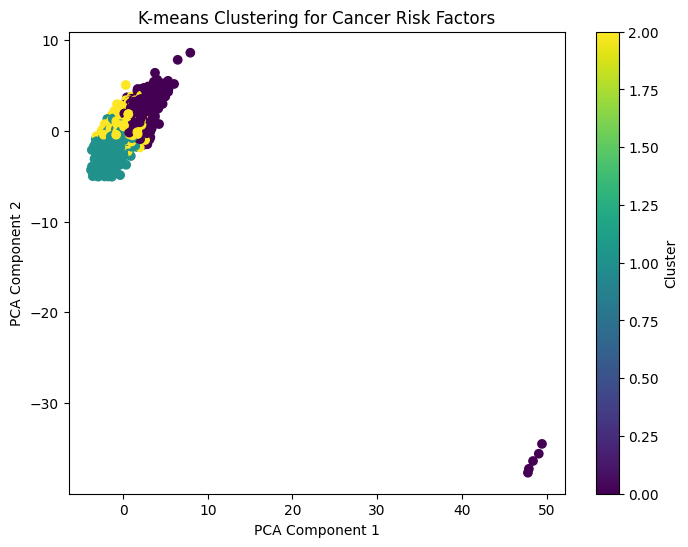

Percentage of individuals in each cancer risk cluster:
High Risk: 49.19%
Medium Risk: 30.27%
Low Risk: 20.54%


In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load the dataset
file_path = '/content/bgd2018.csv'  # Update the file path
df_ncd = pd.read_csv(file_path)

# Rename columns for consistency based on earlier renaming steps
df_ncd.rename(columns={
    't1': 'currently_smoking',
    'a4': 'drinking_alcohol',
    'h2a': 'had_high_bp',
    'h7a': 'had_high_glucose',
    'h13a': 'high_cholesterol',
    'h20f': 'advice_to_lose_weight',
    'h20a': 'advice_to_not_smoke',
    'cx1': 'cervical_cancer_screening_test',
    'cx6': 'result_of_cervical_cancer_test',
    'm14': 'waist',
    'm6a': 'systolic',
    'm6b': 'diastolic',
    'm11' : 'hight',
    'm12': 'weight',
    'm16c': 'heart_rate_reading',
    'b5': 'fasting_blood_glucose',
    'b8': 'cholsterol',
    'b16': 'triglycerides',
    'b17': 'hdl'
}, inplace=True)

# Replace missing values in continuous columns with the mean
columns_to_replace_with_mean = ['drinking_alcohol', 'had_high_bp', 'had_high_glucose', 'high_cholesterol',
                                'advice_to_lose_weight', 'advice_to_not_smoke', 'cervical_cancer_screening_test',
                                'result_of_cervical_cancer_test', 'hight', 'weight', 'waist', 'systolic',
                                'diastolic', 'heart_rate_reading', 'fasting_blood_glucose', 'cholsterol',
                                'triglycerides', 'hdl', 'ldl']

for col in columns_to_replace_with_mean:
    df_ncd[col].fillna(df_ncd[col].mean(), inplace=True)

# Keeping the relevant columns for clustering
columns_to_keep = ['currently_smoking', 'drinking_alcohol', 'had_high_bp', 'had_high_glucose', 'high_cholesterol',
                   'waist', 'systolic', 'diastolic', 'hight', 'weight', 'fasting_blood_glucose', 'cholsterol',
                   'triglycerides', 'hdl', 'ldl']
df_ncd = df_ncd[columns_to_keep]

# Normalize the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_ncd)

# Apply K-means clustering (3 clusters for Low, Medium, High cancer risk)
kmeans = KMeans(n_clusters=3, random_state=42)
df_ncd['cancer_risk_cluster'] = kmeans.fit_predict(scaled_data)

# Visualizing the clusters using PCA (reducing dimensions to 2D for visualization)
pca = PCA(n_components=2)
reduced_data = pca.fit_transform(scaled_data)

plt.figure(figsize=(8, 6))
plt.scatter(reduced_data[:, 0], reduced_data[:, 1], c=df_ncd['cancer_risk_cluster'], cmap='viridis')
plt.title('K-means Clustering for Cancer Risk Factors')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(label='Cluster')
plt.show()

# Calculate and display the percentage of individuals in each cluster (Low, Medium, High risk)
cluster_counts = df_ncd['cancer_risk_cluster'].value_counts(normalize=True) * 100
cluster_labels = {0: 'Low', 1: 'Medium', 2: 'High'}  # Map cluster numbers to risk labels (you may adjust this based on interpretation)

print("Percentage of individuals in each cancer risk cluster:")
for cluster, percentage in cluster_counts.items():
    print(f"{cluster_labels[cluster]} Risk: {percentage:.2f}%")
